# Calculating Forces and Power in Drilling Processes

In [43]:
from pathlib import Path
import sys

# Scripts start from their location; interactive cells start from the working directory.
_settings_start = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
for _settings_root in (_settings_start, *_settings_start.parents):
    if (_settings_root / 'repo_settings.py').is_file():
        if str(_settings_root) not in sys.path:
            sys.path.insert(0, str(_settings_root))
        break
else:
    raise FileNotFoundError(
        "Cannot find repo_settings.py. Run interactive cells from within the repository."
    )

from repo_settings import configure_plots

configure_plots()

import numpy as np
import matplotlib.pyplot as plt

# Tool
alpha = np.pi/6           # rad, 90 - 120/2
D_tool = 16               # mm

# Cutting parameters
Vc_max = 180              # m/min, nominal
f_tooth = 0.1             # mm/rev          -> assumption!
n_teeth = 2               # number of teeth -> assumption!

# Specific cutting and feed forces
Kc = 800                 # MPa = N/mm²
Kf = Kc * 0.4

# Hole
D_hole = 16              # mm
L_hole = 10              # mm

Calculate time history of the feed force and power.

Formulas:
$$
F_f = K_f \cdot F_c \\
P_f = F_f \cdot v_f
$$

In [44]:
# --- Machining parameters calculation ---
# Assuming to keep Vc_max = const -> N = const
N = Vc_max * 1000 / (np.pi * D_tool)  # rpm
# Vf = const too!
Vf = N * f_tooth * n_teeth  # mm/min

# --- Numerical simulation of the drilling process ---
dt = 1/(5*N/60)
t0 = 0.1            # touching instant
t1 = t0 + (D_hole / 2) * np.tan(alpha) / (Vf / 60)  # full engagement [s]
ti = t0
t = np.arange(0, t0, dt).tolist()

# Forces and power per tooth
Fc = np.zeros_like(t).tolist()
Ff = np.zeros_like(t).tolist()
Pf = np.zeros_like(t).tolist()

dz = (Vf / 60) * dt  # mm; dt is in seconds
z = 0.0     # feed coordinate
r = 0.0     # cutting depth coordinate (radius from the center)
while z < L_hole:
  r = min(z/np.tan(alpha), D_hole/2)
  
  t.append(ti)
  Fc.append(Kc * r * f_tooth)
  Ff.append(Kf * Fc[-1])
  Pf.append(Ff[-1] * Vf / (60 * 1000))  # Watts

  z += dz
  ti += dt

t.append(ti)
Fc.append(0); Ff.append(0); Pf.append(0)

Pf_tot = np.array(Pf) * n_teeth  # total feed power

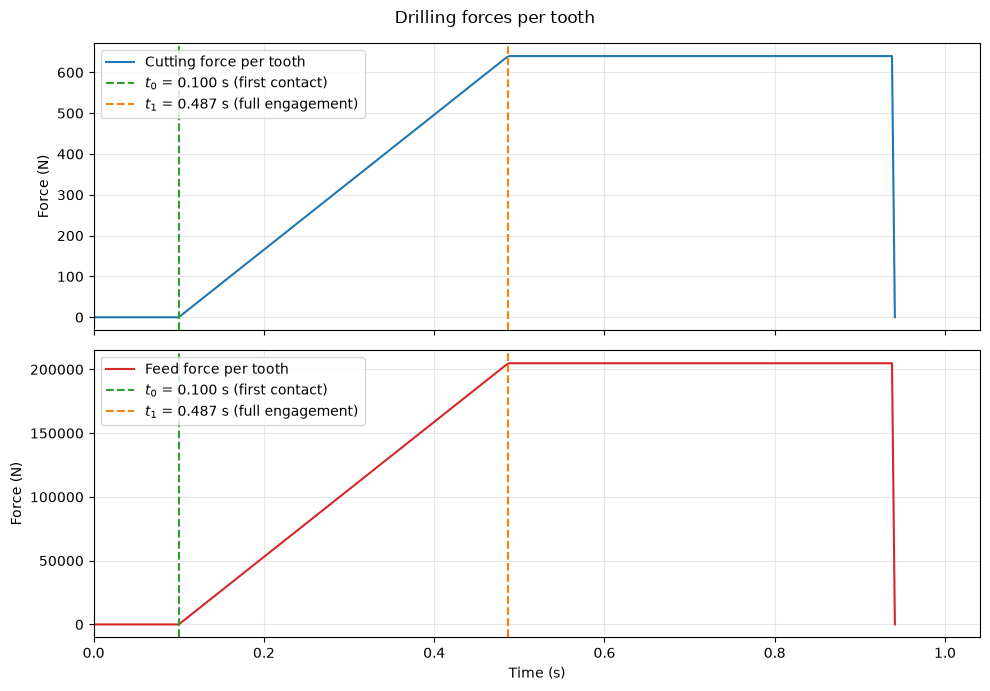

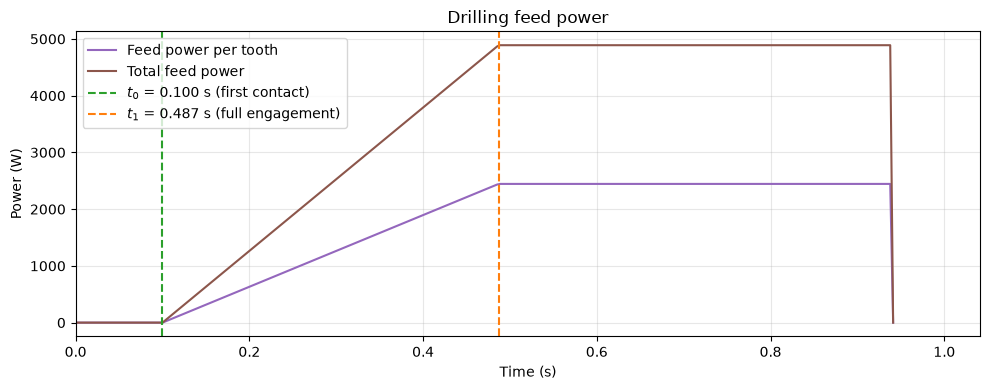

In [45]:
# Figure 1: cutting and feed forces per tooth
fig_forces, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, values, name, color in zip(
    axes, (Fc, Ff),
    ("Cutting force per tooth", "Feed force per tooth"),
    ("tab:blue", "tab:red")
):
    ax.plot(t, values, color=color, label=name)
    ax.set_ylabel("Force (N)")
axes[-1].set_xlabel("Time (s)")
fig_forces.suptitle("Drilling forces per tooth")

# Figure 2: both feed power curves on the same axes
fig_power, ax_power = plt.subplots()
ax_power.plot(t, Pf, color="tab:purple", label="Feed power per tooth")
ax_power.plot(t, Pf_tot, color="tab:brown", label="Total feed power")
ax_power.set_xlabel("Time (s)")
ax_power.set_ylabel("Power (W)")
ax_power.set_title("Drilling feed power")

# Common time markers, full time range, and grid
for ax in [*axes, ax_power]:
    ax.axvline(t0, color="tab:green", linestyle="--",
               label=fr"$t_0$ = {t0:.3f} s (first contact)")
    ax.axvline(t1, color="tab:orange", linestyle="--",
               label=fr"$t_1$ = {t1:.3f} s (full engagement)")
    ax.set_xlim(0, max(t) + t0)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

fig_forces.tight_layout()
fig_power.tight_layout()
plt.show()
